In [25]:
# step 1 : load quires in python 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# load data in python
df = pd.read_excel(r"C:\Users\pc\Downloads\AI_Usage_trend.xlsx")


In [26]:
#  step 2 :Top 5 row
df.head(5)

,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend
0,U0217,30.0,Male,United States,Professional,Bachelor's,Customer Support Specialist,8903.0,ChatGPT,Customer Support,5.7,Resolving customer inquiries using AI chatbot ...,0.0,9.9,3,9.0,11.4,8.4,Yes
1,U0264,35.0,Female,Brazil,Professional,Bachelor's,Desenvolvedora de Software / Software Developer,1367.0,Meta AI,Coding,1.7,Usar GitHub Copilot para autocompletar cÃ³digo...,20.0,5.6,4,5.0,6.4,9.6,Maybe
2,U0246,32.0,Male,France,Professional,Bachelor's,DÃ©veloppeur Full Stack,4466.0,ChatGPT,Coding,1.2,"Automated code review with AI-powered linters,...",20.0,3.0,2,5.0,6.6,6.4,Yes
3,U0177,32.0,Male,Philippines,Professional,High School,Social Media Content Creator,486.0,ChatGPT,Content Creation,2.0,Creating Instagram/TikTok captions with AI wri...,0.0,6.5,2,5.0,3.2,6.4,Yes
4,U0207,16.0,Male,Philippines,Student,Undergraduate,Digital Media Production Student,132.0,Claude,Content Creation,1.6,"Creating YouTube video scripts, Designing soci...",30.0,4.7,4,6.0,3.8,3.8,Yes


In [27]:
#  Step 3:shape data 
df.shape

(141, 19)

In [28]:
# Steop 4:find null
df.isnull().sum()

User_ID                        0
Age                            1
Gender                         0
Country                        0
User_Type                      0
Education_Level                0
Profession                     0
Monthly_Income                 2
AI_Tool                        0
AI_Purpose                     0
AI_Usage_Hours_Per_Day         0
Tasks_Performed                0
Monthly_AI_Cost                1
Productivity_Score             0
Accuracy_Rating                0
Satisfaction_Score             1
Time_Saved_Hours_Per_Week      1
Work_or_Study_Hours_Per_Day    0
Would_Recommend                0
dtype: int64

In [29]:
# step 5: fill null
# fill null valu in Age column
df["Age"]=df["Age"].fillna(df["Age"].mean())
# fill null valu in Monthaly_Income
df["Monthly_Income"]=df["Monthly_Income"].fillna(df["Monthly_Income"].median())
# fill null valu in Monthly_AI_Cost
df["Monthly_AI_Cost"]=df["Monthly_AI_Cost"].fillna(df["Monthly_AI_Cost"].mean())
#fill null  in Satisfaction_Score
df["Satisfaction_Score"]=df["Satisfaction_Score"].fillna(df["Satisfaction_Score"].mean())
# fill null in Time_Saved_Hours_Day
df["Time_Saved_Hours_Per_Week"]=df["Time_Saved_Hours_Per_Week"].fillna(df["Time_Saved_Hours_Per_Week"].mean())


In [30]:
# step 6: finaly saw data
df.isnull().sum()

User_ID                        0
Age                            0
Gender                         0
Country                        0
User_Type                      0
Education_Level                0
Profession                     0
Monthly_Income                 0
AI_Tool                        0
AI_Purpose                     0
AI_Usage_Hours_Per_Day         0
Tasks_Performed                0
Monthly_AI_Cost                0
Productivity_Score             0
Accuracy_Rating                0
Satisfaction_Score             0
Time_Saved_Hours_Per_Week      0
Work_or_Study_Hours_Per_Day    0
Would_Recommend                0
dtype: int64

In [31]:
# Step 7:find duplicated values
df.duplicated().sum()

np.int64(0)

In [32]:
# Step 8:Statical value 
round(df.describe(),2)

,Age,Monthly_Income,AI_Usage_Hours_Per_Day,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day
count,141.00,141.00,141.00,141.00,141.00,141.00,141.00,141.00,141.00
mean,29.93,3204.19,2.97,10.50,5.17,3.41,6.08,6.05,7.26
std,11.46,21024.86,2.71,14.25,1.75,0.82,1.44,4.03,1.73
min,16.00,0.00,0.50,0.00,1.80,2.00,3.00,0.00,2.10
25%,22.00,113.00,1.30,0.00,3.90,3.00,5.00,3.00,6.10
50%,27.00,578.00,2.00,0.00,5.00,3.00,6.00,5.60,7.30
75%,35.00,1991.00,4.00,20.00,6.50,4.00,7.00,8.00,8.40
max,97.00,250000.00,23.00,100.00,9.90,5.00,9.00,19.40,12.00


In [33]:
#Step 9:copy data
df_clean=df.copy()

In [34]:
#Step 10:Save Data
df_clean.to_csv(
    r"C:\Users\pc\Downloads\AI_Usage_Cleaned.csv",
    index=False
)

Exploratory Data Analysis (EDA)


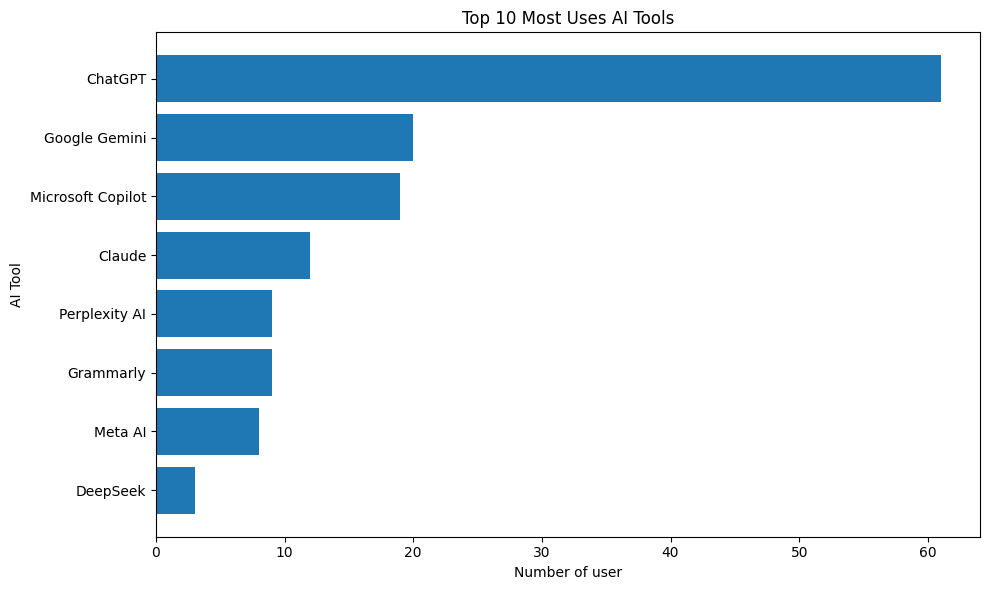

In [35]:
#1.Which AI tools are most popular among users based on the number of users?
AI_tool_count=df["AI_Tool"].value_counts()
Top10_AI=AI_tool_count.head(10)
plt.figure(figsize=(10,6))
plt.barh(Top10_AI.index,Top10_AI.values)
plt.title("Top 10 Most Uses AI Tools")
plt.xlabel("Number of user")
plt.ylabel("AI Tool")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


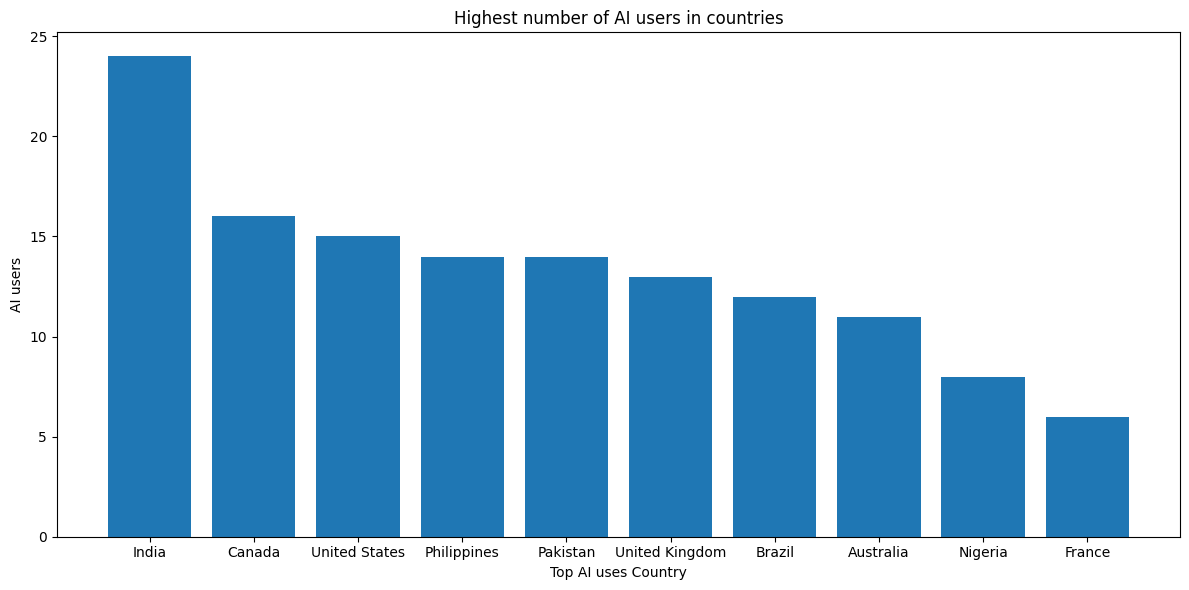

In [36]:
#2.Which countries have the highest number of AI users?
Count_Country=df["Country"].value_counts()
Highest_user=Count_Country.head(10)
plt.figure(figsize=(12,6))
plt.bar(Highest_user.index,Highest_user.values)
plt.title("Highest number of AI users in countries")
plt.xlabel("Top AI uses Country")
plt.ylabel("AI users")
plt.tight_layout()
plt.show()

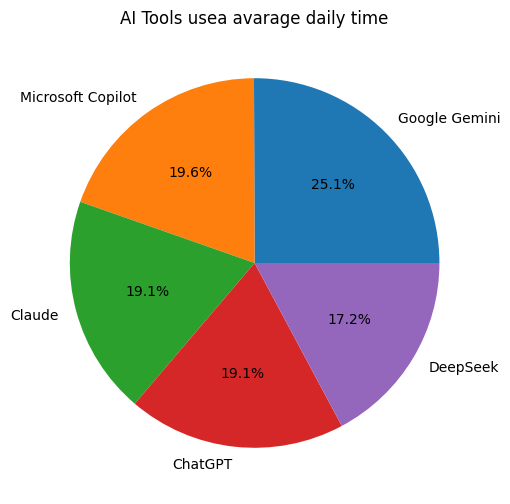

In [37]:
#3.Which AI tools have the highest average daily usage time?
Tool_usage=df_clean.groupby("AI_Tool")["AI_Usage_Hours_Per_Day"].mean()
Top5_Tool=Tool_usage.nlargest(5)
plt.figure(figsize=(6,6))
plt.pie(Top5_Tool.values,labels=Top5_Tool.index,autopct="%1.1f%%")
plt.title("AI Tools usea avarage daily time")
plt.show()


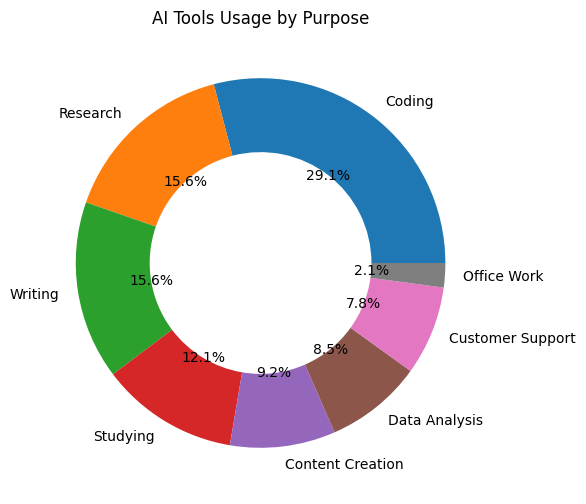

In [38]:
#4.What are the most common purposes for using AI tools?
Purpose_count=df_clean["AI_Purpose"].value_counts()
plt.figure(figsize=(6,6))
plt.pie(Purpose_count.values,labels=Purpose_count.index,autopct="%1.1f%%", wedgeprops={"width": 0.4})
plt.title("AI Tools Usage by Purpose")
plt.show()



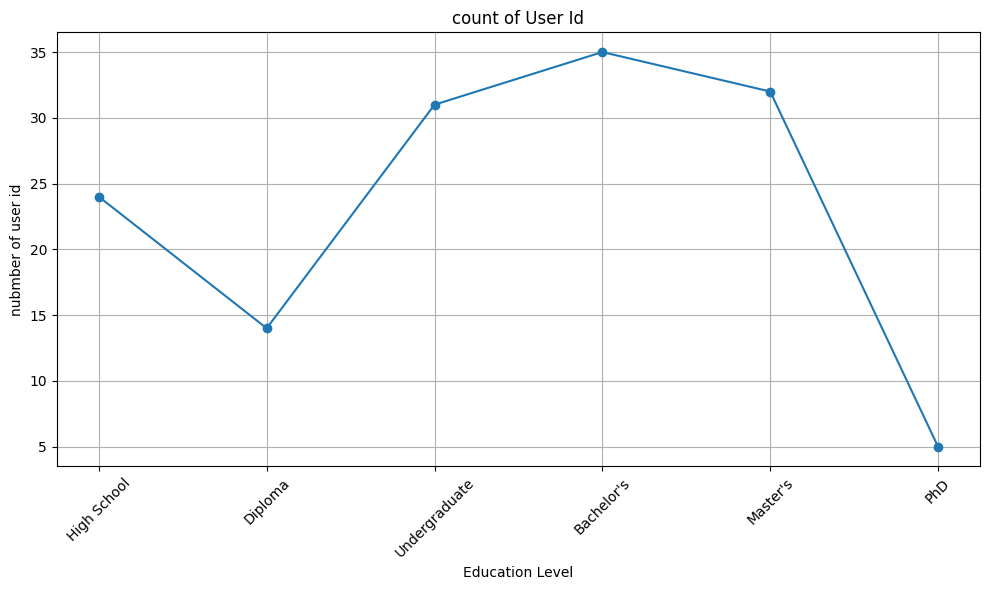

In [43]:
# 5 eduction level wise Average ai usage
education_order = [
    "High School",
    "Diploma",
    "Undergraduate",
    "Bachelor's",
    "Master's",
    "PhD"]
df_clean["Education_Level"] = pd.Categorical(
    df_clean["Education_Level"],
    categories=education_order,
    ordered=True)
df_clean = df_clean.sort_values("Education_Level")
Education_Usage = (df_clean.groupby("Education_Level", observed=True)["User_ID"].count())
plt.figure(figsize=(10, 6))
plt.plot(Education_Usage.index,Education_Usage.values,marker='o')
plt.title("count of User Id")
plt.xlabel("Education Level")
plt.ylabel("nubmber of user id")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()



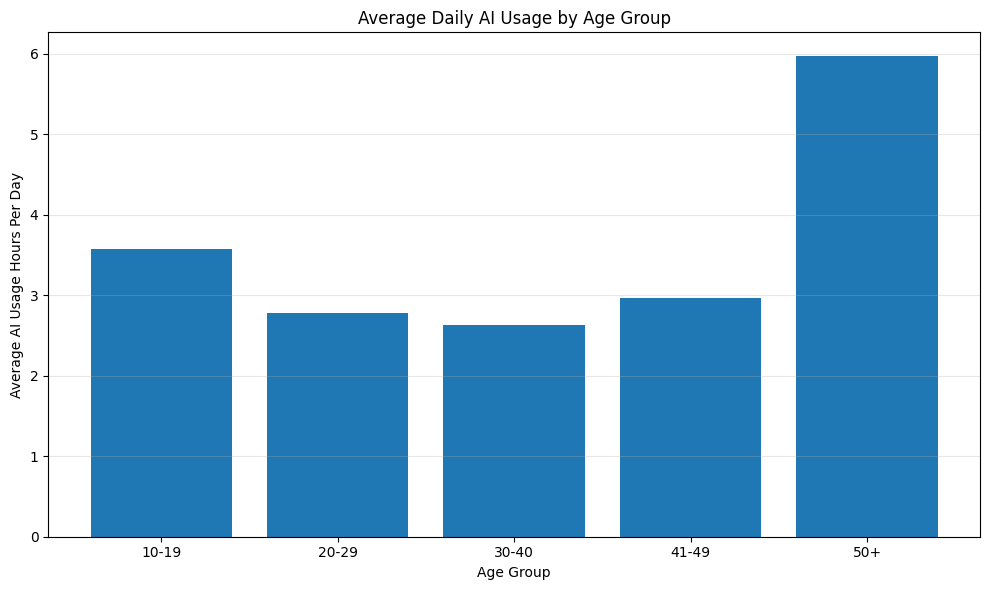

In [47]:
#6.Relationship between Age and AI Usage
import numpy as np
bins = [10, 20, 30, 41, 50, np.inf]
labels = ["10-19", "20-29", "30-40", "41-49", "50+"]
df_clean["Age_Group"] = pd.cut(
    df_clean["Age"],
    bins=bins,
    labels=labels,
    right=False
)
# Calculate average AI usage by age group
age_usage = (
    df_clean.groupby("Age_Group", observed=False)
    ["AI_Usage_Hours_Per_Day"].mean()
)
plt.figure(figsize=(10, 6))
plt.bar(age_usage.index.astype(str), age_usage.values)
plt.title("Average Daily AI Usage by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average AI Usage Hours Per Day")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

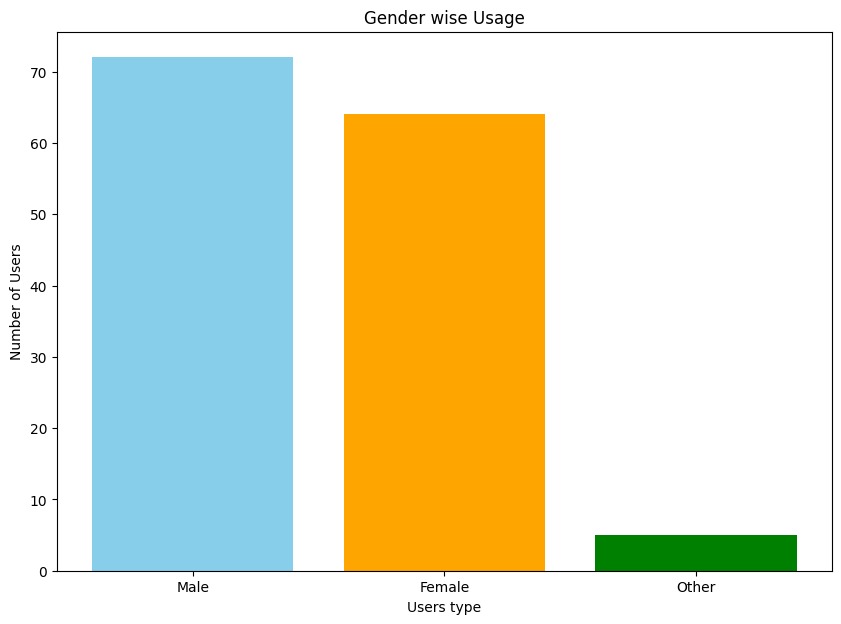

In [41]:
#7.AI Usage by Gender
Gender_AI_Usage=df_clean["Gender"].value_counts()
plt.figure(figsize=(10,7))
plt.bar(Gender_AI_Usage.index,Gender_AI_Usage.values, color=["skyblue", "orange","green"])
plt.title("Gender wise Usage")
plt.xlabel("Users type")
plt.ylabel("Number of Users")
plt.show()